In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
femalexample = pd.read_csv("gender_submission.csv")

In [9]:
print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", femalexample.shape)

Training shape: (891, 12)
Test shape: (418, 11)
Submission shape: (418, 2)


In [10]:
train.info() # checking for null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [11]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [12]:
femalexample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB


In [16]:
print(train["Survived"].value_counts()) # counting how many people survived and died, 0 = dead, 1 = alive.

Survived
0    549
1    342
Name: count, dtype: int64


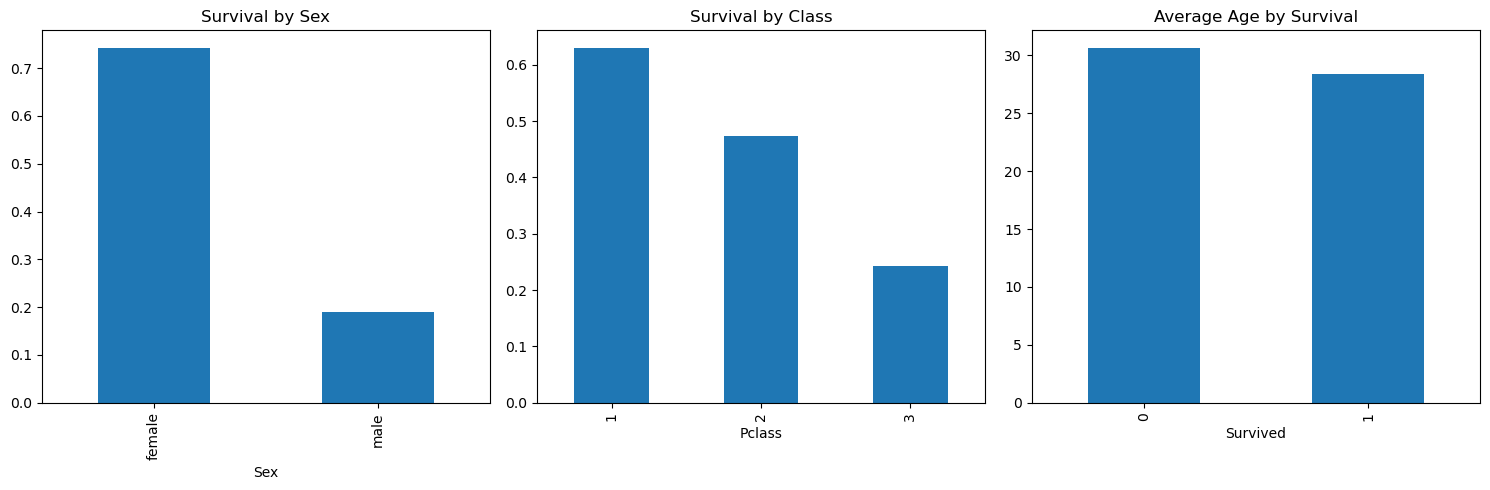

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Survival by sex
train.groupby("Sex")["Survived"].mean().plot(
    kind="bar", ax=axes[0], title="Survival by Sex"
)

# Survival by passenger class
train.groupby("Pclass")["Survived"].mean().plot(
    kind="bar", ax=axes[1], title="Survival by Class"
)

# Survival by age
train.groupby("Survived")["Age"].mean().plot(
    kind="bar", ax=axes[2], title="Average Age by Survival"
)

plt.tight_layout()
plt.show()

In [24]:
# We are going to use three features for our model
# PClass: This determined where you sat on the Titanic, with upper classes sitting in B-C decks and boat deck, while lower classes sitting in C and below decks.
# Age: The older you are, the slower you are, which means evacuating takes longer
# Sex: Women and children were evacuated first
from sklearn.model_selection import train_test_split
X = train[["Pclass", "Sex", "Age"]]
y = train["Survived"]

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
X_train.isnull().sum() # Let's replace the null values in Age with the median

Pclass      0
Sex         0
Age       137
dtype: int64

In [38]:
median_age = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(median_age)
X_val["Age"] = X_val["Age"].fillna(median_age)

In [39]:
print(X_train["Age"].isnull().sum())
print(X_val["Age"].isnull().sum()) 

0
0


In [41]:
X_train["Sex"] = X_train["Sex"].map({
    "male" : 1,
    "female" : 2
})
X_val["Sex"] = X_val["Sex"].map({
    "male" : 1,
    "female" : 2
})

In [58]:
X_train = X_train.drop(columns="NewAge") # accidentally added a column
X_train.isnull().sum() # lets check again that there are no null values
X_val.isnull().sum()

Pclass    0
Sex       0
Age       0
dtype: int64

In [59]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [62]:
predictions = model.predict(X_val)

In [65]:
from sklearn.metrics import accuracy_score
val_accuracy = accuracy_score(y_val, predictions)
val_accuracy 

0.7318435754189944

In [68]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1 # Creating a new feature called FamilySize
train["IsAlone"] = train["FamilySize"] == 1 # Creating a new feature called IsAlone(does the passenger have family or is travelling alone?)

In [69]:
print(train.groupby("FamilySize")["Survived"].mean())
print(train.groupby("IsAlone")["Survived"].mean())

FamilySize
1     0.303538
2     0.552795
3     0.578431
4     0.724138
5     0.200000
6     0.136364
7     0.333333
8     0.000000
11    0.000000
Name: Survived, dtype: float64
IsAlone
False    0.505650
True     0.303538
Name: Survived, dtype: float64


In [71]:
from sklearn.model_selection import train_test_split
X2 = train[["Pclass", "Sex", "Age", "FamilySize", "IsAlone"]]
y2 = train["Survived"]

# Split into training and validation sets
X_train2, X_val2, y_train2, y_val2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y
)

In [72]:
X_train2.isnull().sum()
X_val2.isnull().sum()

Pclass         0
Sex            0
Age           40
FamilySize     0
IsAlone        0
dtype: int64

In [79]:
median_age2 = X_train2["Age"].median() # clearing up null values again
X_train2["Age"] = X_train2["Age"].fillna(median_age2)
X_val2["Age"] = X_val2["Age"].fillna(median_age2)
X_train2["Sex"] = X_train2["Sex"].map({
    "male" : 1,
    "female" : 2
})
X_val2["Sex"] = X_val2["Sex"].map({
    "male" : 1,
    "female" : 2
})
print(X_train2["Age"].isnull().sum())
print(X_val2["Age"].isnull().sum()) 

0
0


In [80]:
model2 = LogisticRegression() # creating the model
model2.fit(X_train2, y_train2)

LogisticRegression()

In [83]:
predictions2 = model2.predict(X_val2)

In [84]:
val_accuracy2 = accuracy_score(y_val2, predictions2)
val_accuracy2 

0.8044692737430168

In [89]:
from sklearn.ensemble import RandomForestClassifier # let's use a different model now
forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

forest_model.fit(X_train2, y_train2)

RandomForestClassifier(max_depth=5, random_state=42)

In [90]:
predictions3 = forest_model.predict(X_val2)

In [91]:
forest_accuracy = accuracy_score(y_val2, predictions3)
forest_accuracy

0.776536312849162

In [92]:
import pandas as pd # let's find out which features the random forest model considers important

feature_importance = pd.DataFrame({
    "Feature": X_train2.columns,
    "Importance": forest_model.feature_importances_
})

display(feature_importance.sort_values("Importance", ascending=False))

,Feature,Importance
1,Sex,0.495311
0,Pclass,0.203959
2,Age,0.180944
3,FamilySize,0.092836
4,IsAlone,0.026949


In [97]:
from sklearn.metrics import classification_report, confusion_matrix # let's move to evaluating the models we used so we can better understand how they work
predictions2 = model2.predict(X_val2)
print(classification_report(y_val2, predictions2))

              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [98]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val2, predictions2)
print(cm)

[[96 14]
 [21 48]]


In [99]:
from sklearn.metrics import classification_report

predictions3 = forest_model.predict(X_val2)

print(classification_report(y_val2, predictions3))

              precision    recall  f1-score   support

           0       0.77      0.90      0.83       110
           1       0.78      0.58      0.67        69

    accuracy                           0.78       179
   macro avg       0.78      0.74      0.75       179
weighted avg       0.78      0.78      0.77       179



In [101]:
from sklearn.metrics import roc_auc_score # This measures how well a model distinguishes between survivors and non-survivors across different classification thresholds.

probabilities = model2.predict_proba(X_val2)[:, 1]

auc = roc_auc_score(y_val2, probabilities)

print("ROC-AUC:", auc)

ROC-AUC: 0.8519104084321476


In [105]:
test["FamilySize"] = test["SibSp"] + test["Parch"] + 1 # Now we can start testing our data!
test["IsAlone"] = test["FamilySize"] == 1
test[["Pclass", "Sex", "Age", "FamilySize", "IsAlone"]].head()

,Pclass,Sex,Age,FamilySize,IsAlone
0,3,male,34.5,1,True
1,3,female,47.0,2,False
2,2,male,62.0,1,True
3,3,male,27.0,1,True
4,3,female,22.0,3,False


In [106]:
test["Age"] = test["Age"].fillna(median_age)
test["Sex"] = test["Sex"].map({"male": 1, "female": 2})
test[["Pclass", "Sex", "Age", "FamilySize", "IsAlone"]].isnull().sum()

Pclass        0
Sex           0
Age           0
FamilySize    0
IsAlone       0
dtype: int64

In [108]:
test_features = test[["Pclass", "Sex", "Age", "FamilySize", "IsAlone"]] # group the features together and then use our model(logistic regression) to predict survival
test_predictions = model2.predict(test_features)
print(test_predictions[:10]) # let's print out some of the predictions

[0 0 0 0 1 0 1 0 1 0]


In [109]:
submission = pd.DataFrame({ # let's put our test results in a CSV with the passenger ids
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

submission.to_csv("submission.csv", index=False)

In [110]:
submission.head() # let's check to see if it worked

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [111]:
print(submission.shape) # checking dimensions and values
print(submission["Survived"].value_counts())
print(submission.isnull().sum())

(418, 2)
Survived
0    266
1    152
Name: count, dtype: int64
PassengerId    0
Survived       0
dtype: int64
